In [1]:
%matplotlib widget
import jax
import jax.numpy as jnp
from dataclasses import dataclass
from jax.tree_util import register_dataclass
import scipy.optimize as scio
import matplotlib.pyplot as plt 
from matplotlib import ticker

from post_process_parquet import calculate_dataframe

import plotly.graph_objects as go

jax.config.update("jax_enable_x64", True) 
jax.config.update("jax_debug_nans", True)
cmap = 'jet'

# data_coupled = calculate_dataframe("2026_10_16_18h29")
data_uncoupled = calculate_dataframe("2026_9_23_18h19")

KeyboardInterrupt: 

In [ ]:
# class SystemParams:
@register_dataclass  # rend la classe jax-compatible
@dataclass
class SystemParams:
    gamma: float = (0.1,)
    w: float = (100 * 2 * jnp.pi,)
    R: float = (10e3,)


w01 = 95 * 2 * jnp.pi
Cp1 = 5.7781e-9
km21 = 0.35342
Q1 = 65.701
M1 = 0.05
ProtoCaracsRef1 = jnp.array([w01, Cp1, km21, Q1, M1])

w02 = 127.96 * 2 * jnp.pi
Cp2 = 3.7888e-9
km22 = 1.1055
Q2 = 66.846
M2 = 0.05
ProtoCaracsRef2 = jnp.array([w02, Cp2, km22, Q2, M2])

In [ ]:
# Fonction qui calcule la puissance


def system_signals(params: SystemParams, vect):
    """
    returns x1, x2, phi_x1, phi_x2, v1, v2, P1in, P2in
    position resonator 1, voltage resonator 1
    position resonator 2, voltage resonator 2
    computed by analytical analysis
    for the two couples linear resonators system
    """

    gamma = params.gamma
    w = params.w
    R = params.R

    w0 = vect[0]
    Cp = vect[1]
    km2 = vect[2]
    Q = vect[3]
    M = vect[4]

    alpha = jnp.sqrt(km2 * M * w0**2 * Cp)
    a = -(w**2) + 1.0j * w * w0 / Q + w0**2
    b = alpha / M
    c = 1.0j * w * alpha
    d = 1.0j * w * Cp + 1 / R

    v = c * gamma / (b * c + d * a)

    P = jnp.abs(v) ** 2 / (2 * R)

    return w, R, P

In [ ]:
# Récupère les listes de fréquences et de résistances et jnp array

frequency_list = jnp.asarray(data_uncoupled['f'])
resistance_list = jnp.asarray(data_uncoupled['Rload'])
power1_exp = jnp.asarray(data_uncoupled['pow1'])
power2_exp = jnp.asarray(data_uncoupled['pow2'])
power1_exp.shape

(23350,)

In [ ]:
# Calcul de la puissance en vmap sur omega et R

vpower = jax.vmap(
    jax.vmap(
        system_signals,
        in_axes=(
            SystemParams(
                gamma=None,
                w=0,
                R=None,
            ),
            None,
        ),
    ),
    in_axes=(
        SystemParams(
            gamma=None,
            w=None,
            R=0,
        ),
        None,
    ),
)


def power(vect):
    params_w = SystemParams(
        gamma=0.1,
        w=frequency_list * 2 * jnp.pi,
        R=resistance_list,
    )

    return vpower(params_w, vect)

In [ ]:
def error1_function(X0):
    caracs = X0 * ProtoCaracsRef1
    w, r, power_sim = power(caracs)
    return (power_sim - power1_exp).flatten()

def error2_function(X0):
    caracs = X0 * ProtoCaracsRef2
    w, r, power_sim = power(caracs)
    return (power_sim - power2_exp).flatten()

In [ ]:
x01 = jnp.ones_like(ProtoCaracsRef1)
res1 = scio.least_squares(error1_function, x01)
xf1 = res1.x
ProtoCaracsOpt1 = xf1 * ProtoCaracsRef1

x02 = jnp.ones_like(ProtoCaracsRef2)
res2 = scio.least_squares(error2_function, x02)
xf2 = res2.x
ProtoCaracsOpt2 = xf2 * ProtoCaracsRef2

print(
    "w01 = {}, \nCp1 = {}, \nkm21 = {}, \nQ1 = {}, \nM1 = {}".format(
        ProtoCaracsOpt1[0] / (2 * jnp.pi), ProtoCaracsOpt1[1], ProtoCaracsOpt1[2], ProtoCaracsOpt1[3], ProtoCaracsOpt1[4]
    )
)

print(
    "w02 = {}, \nCp2 = {}, \nkm22 = {}, \nQ2 = {}, \nM2 = {}".format(
        ProtoCaracsOpt2[0] / (2 * jnp.pi), ProtoCaracsOpt2[1], ProtoCaracsOpt2[2], ProtoCaracsOpt2[3], ProtoCaracsOpt2[4]
    )
)

In [59]:
w_grid, R_grid, power1_th = power(ProtoCaracsOpt1)
f_grid = w_grid / (2. * jnp.pi)

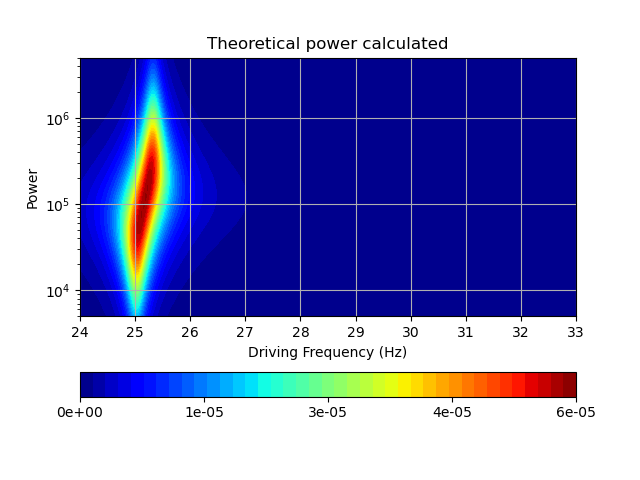

In [78]:
plt.figure()
plt.contourf(f_grid, R_grid, power1_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
# plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [61]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power1_exp*1.e6, opacity=0.5),
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power1_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

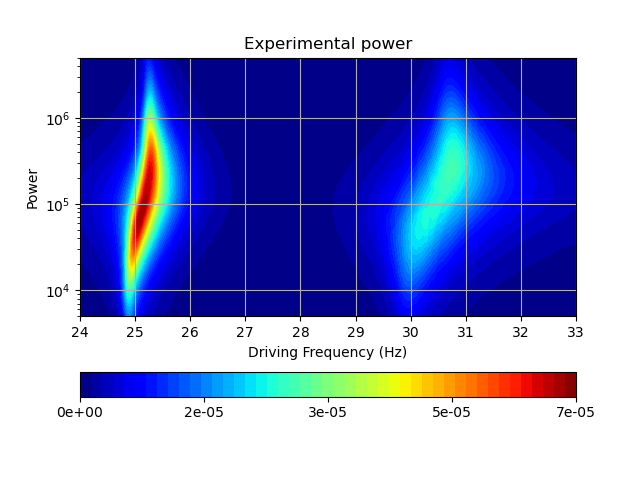

In [62]:
plt.figure()
plt.contourf(frequency_list, resistance_list, power1_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [63]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=(power1_th - power1_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_99023/196319669.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



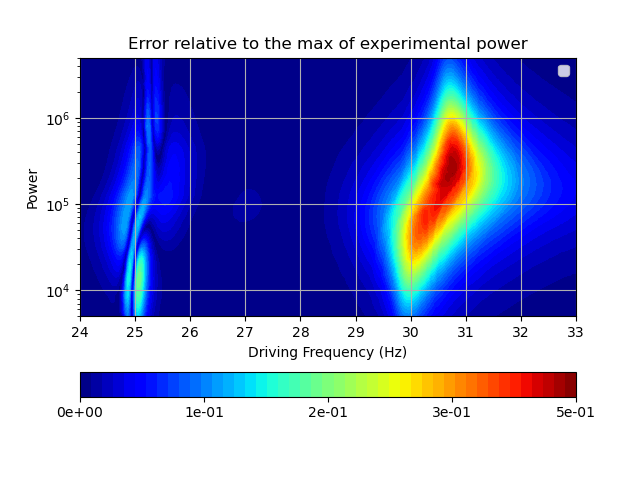

In [64]:
plt.figure()
plt.contourf(
    frequency_list,
    resistance_list,
    abs(power1_exp - power1_th) / (power1_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

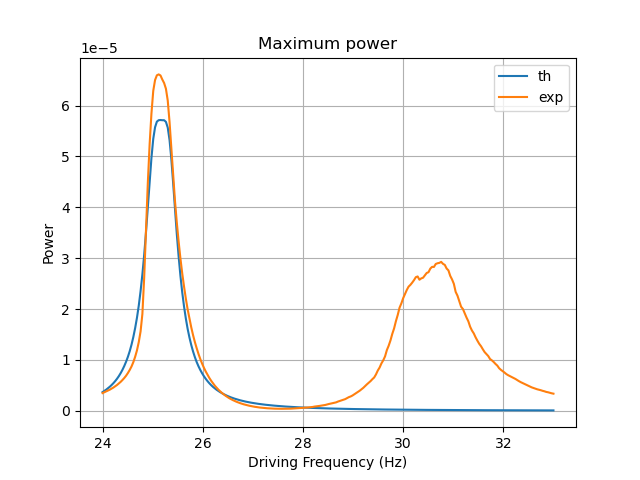

In [65]:
plt.figure()
plt.plot(frequency_list, power1_th.max(axis=0), label="th")
plt.plot(frequency_list, power1_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()

In [66]:
w_grid, R_grid, power2_th = power(ProtoCaracsOpt2)
f_grid = w_grid / (2. * jnp.pi)

/tmp/ipykernel_99023/3445507096.py:8: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



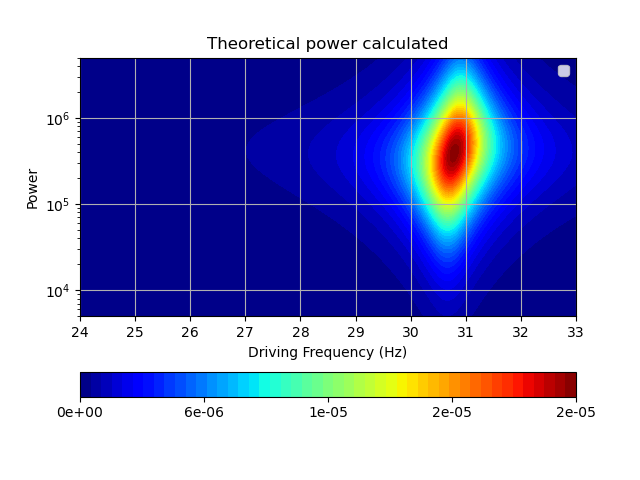

In [67]:
plt.figure()
plt.contourf(f_grid, R_grid, power2_th, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Theoretical power calculated")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [68]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power2_exp*1.e6, opacity=0.5),
    # go.Surface(x=f_grid, y=jnp.log10(R_grid), z=power2_th*1.e6, opacity = .5, showscale=False, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

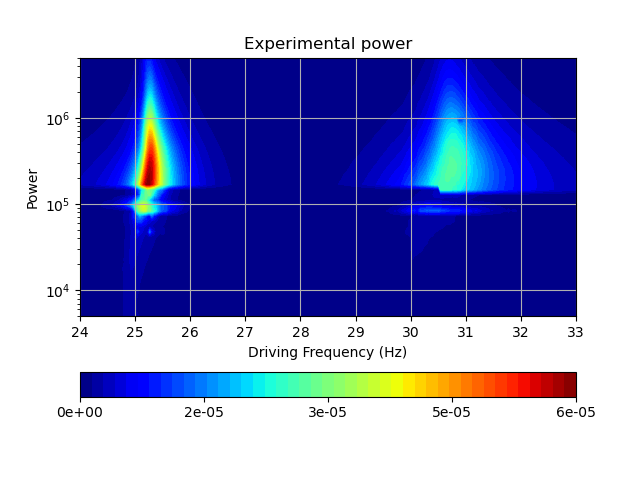

In [69]:
plt.figure()
plt.contourf(frequency_list, resistance_list, power2_exp, 50, cmap=cmap)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Experimental power")
#plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

In [70]:
fig = go.Figure(data=[
    go.Surface(x=f_grid, y=jnp.log10(R_grid), z=(power2_th - power2_exp)*1.e6, opacity=0.5, colorscale="jet"),

])

def update(fig):
    fig.update_layout(scene = dict(
                      xaxis=dict(
                          title=dict(
                              text='Frequency, f [Hz]'
                          )
                      ),
                      yaxis=dict(
                          title=dict(
                              text='Resistance, R [log10(Ohm)]'
                          )
                      ),
                      zaxis=dict(
                          title=dict(
                              text='Power [muW]'
                          )
                      ),
                    ),
                    width=700,
                    margin=dict(r=20, b=10, l=10, t=10))
update(fig)
fig.show()

/tmp/ipykernel_99023/2033670759.py:14: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



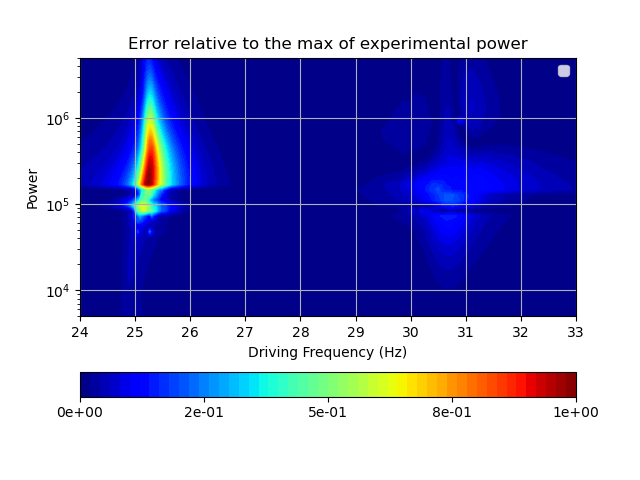

In [71]:
plt.figure()
plt.contourf(
    frequency_list,
    resistance_list,
    abs(power2_exp - power2_th) / (power2_exp.max(axis=1).max(axis=0)),
    50,
    cmap=cmap,
)
locator = ticker.LinearLocator(numticks=5)
cbar = plt.colorbar(orientation="horizontal", format="%.e", ticks=locator)
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Error relative to the max of experimental power")
plt.legend()
plt.yscale("log")
plt.grid()
plt.show()

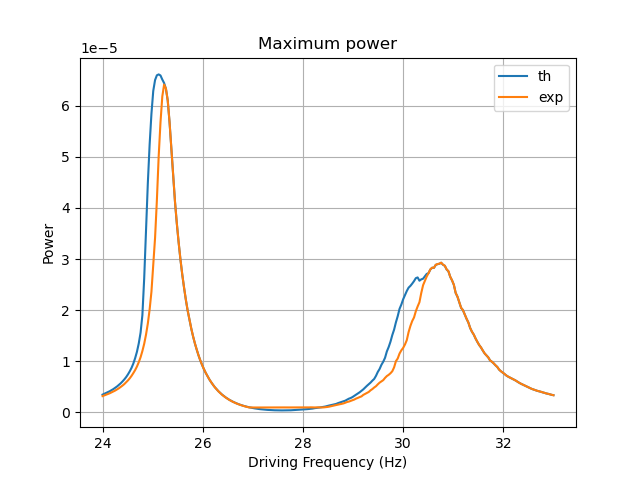

In [74]:
plt.figure()
plt.plot(frequency_list, power1_exp.max(axis=0), label="th")
plt.plot(frequency_list, power2_exp.max(axis=0), label="exp")
plt.xlabel("Driving Frequency (Hz)")
plt.ylabel("Power")
plt.title("Maximum power")
plt.legend()
plt.grid()
plt.show()